# UNEMPLOYMENT ANALYSIS WITH PYTHON

## Internship Project

### Introduction
Unemployment is one of the major economic challenges in India.
This project analyzes unemployment rates across different
regions of India using Python.

### Objectives
1. To study unemployment trends in India.
2. To compare unemployment rates across different regions.
3. To compare rural and urban unemployment.
4. To visualize unemployment data using graphs.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../data/raw/Unemployment in India.csv")

df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [4]:
print("Number of Rows and Columns:", df.shape)

Number of Rows and Columns: (768, 7)


In [5]:
print("Columns Names:")
print(df.columns)

Columns Names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 66.1 KB


In [7]:
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [8]:
df.dropna(how='all', inplace=True)

print("Dataset shape after removing empty rows:", df.shape)

Dataset shape after removing empty rows: (740, 7)


In [9]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')


In [10]:
df['Region'] = df['Region'].str.strip()
df['Area'] = df['Area'].str.strip()

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [11]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

print("Date column converted successfully!")
df[['Date']].head()

Date column converted successfully!


,Date
0,2019-05-31
1,2019-06-30
2,2019-07-31
3,2019-08-31
4,2019-09-30


In [12]:
df.dtypes

Region                                                str
Date                                       datetime64[us]
Frequency                                             str
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                                  str
dtype: object

In [13]:
numeric_columns = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Numerical columns converted successfully!")

Numerical columns converted successfully!


In [14]:
print("Final Dataset Shape:", df.shape)

df.head()

Final Dataset Shape: (740, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [15]:
print("Statistical Summary:")
df.describe()

Statistical Summary:


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [16]:
average_unemployment = df['Estimated Unemployment Rate (%)'].mean()

print("Average Unemployment Rate in India:",
      round(average_unemployment, 2), "%")

Average Unemployment Rate in India: 11.79 %


In [17]:
region_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

print(region_unemployment)

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64


In [18]:
print("Highest Unemployment Region:")
print(region_unemployment.idxmax(),
      round(region_unemployment.max(), 2), "%")

print("\nLowest Unemployment Region:")
print(region_unemployment.idxmin(),
      round(region_unemployment.min(), 2), "%")

Highest Unemployment Region:
Tripura 28.35 %

Lowest Unemployment Region:
Meghalaya 4.8 %


In [19]:
area_unemployment = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

print(area_unemployment)

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


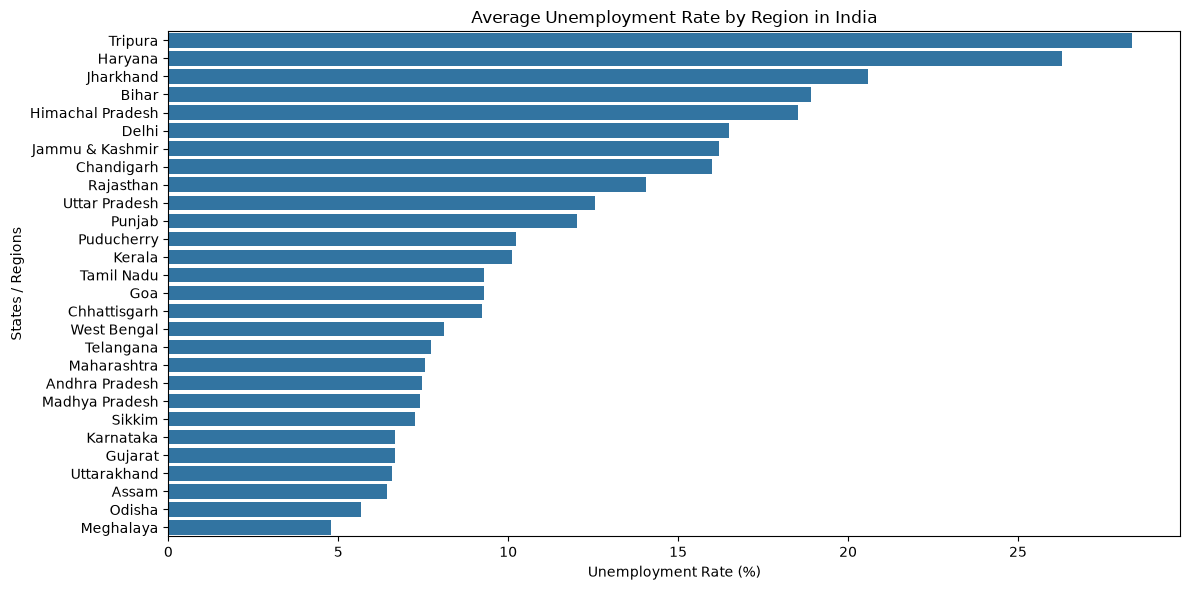

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=region_unemployment.values,
    y=region_unemployment.index
)

plt.title("Average Unemployment Rate by Region in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("States / Regions")
plt.tight_layout()

plt.show()

In [22]:
import os

os.makedirs("../outputs/figures", exist_ok=True)

print("Figures folder is ready!")

Figures folder is ready!


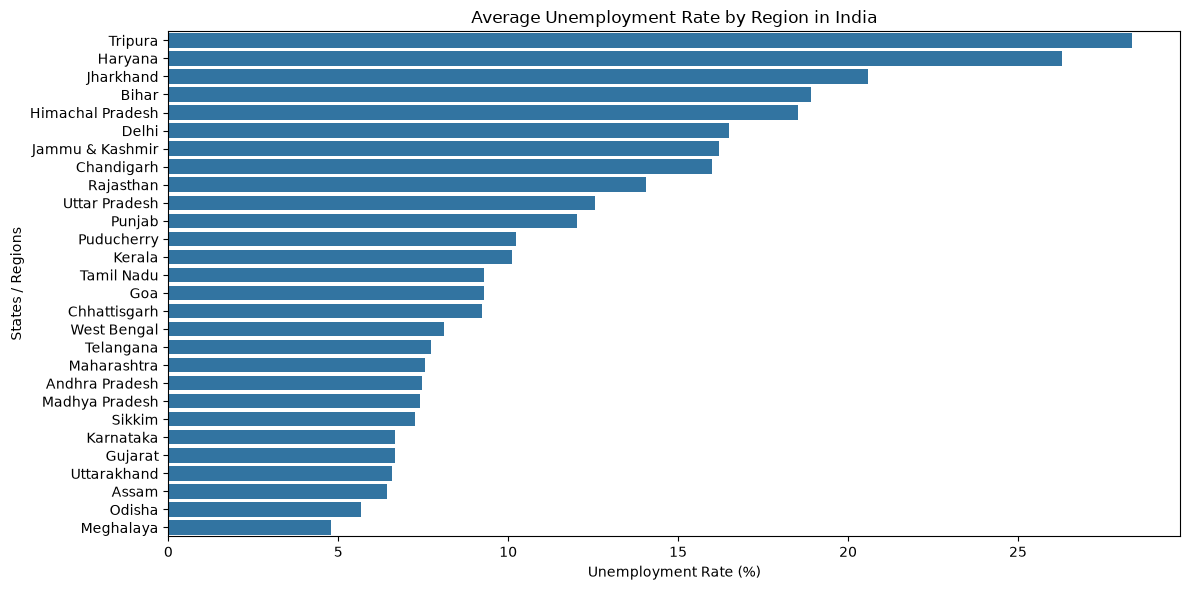

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=region_unemployment.values,
    y=region_unemployment.index
)

plt.title("Average Unemployment Rate by Region in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("States / Regions")

plt.tight_layout()
plt.savefig("../outputs/figures/unemployment_by_region.png",
            dpi=300, bbox_inches="tight")

plt.show()

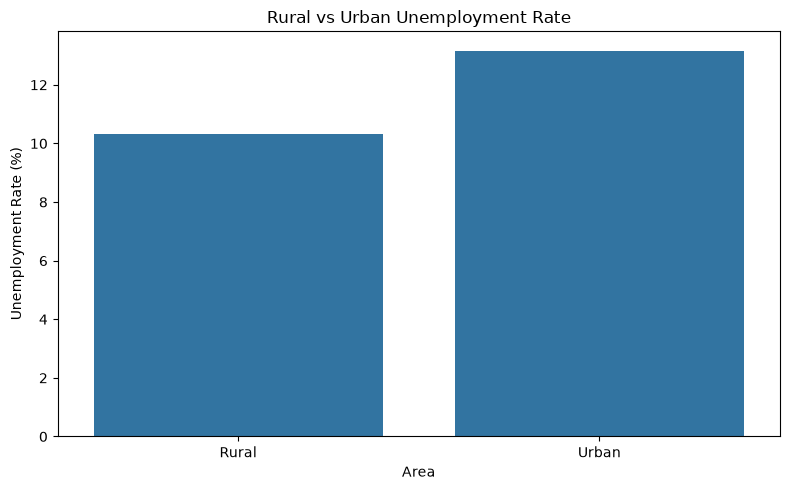

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title("Rural vs Urban Unemployment Rate")
plt.xlabel("Area")
plt.ylabel("Unemployment Rate (%)")

plt.tight_layout()
plt.savefig("../outputs/figures/rural_vs_urban.png",
            dpi=300, bbox_inches="tight")
plt.show()

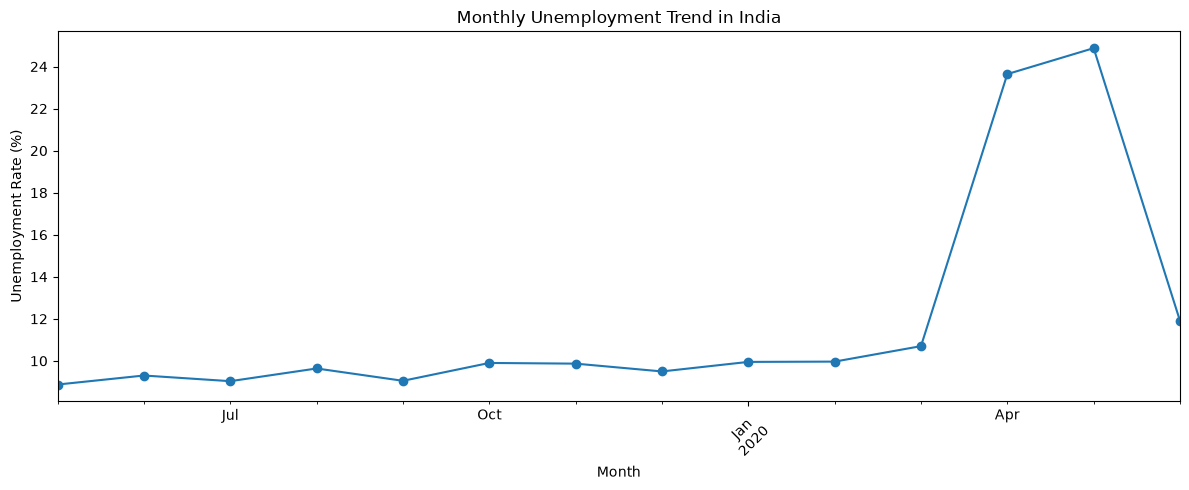

In [25]:
monthly_unemployment = df.groupby(
    df['Date'].dt.to_period('M')
)['Estimated Unemployment Rate (%)'].mean()

plt.figure(figsize=(12, 5))

monthly_unemployment.plot(marker='o')

plt.title("Monthly Unemployment Trend in India")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../outputs/figures/monthly_trend.png",
            dpi=300, bbox_inches="tight")
plt.show()

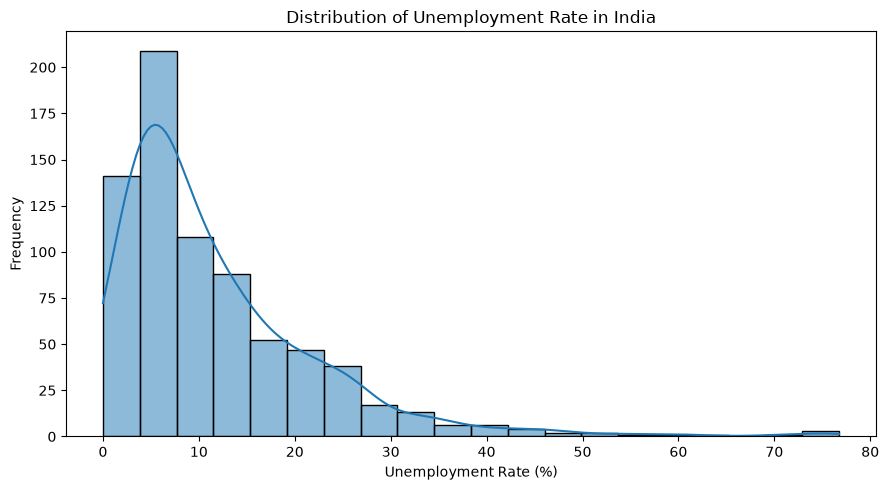

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df['Estimated Unemployment Rate (%)'],
    bins=20,
    kde=True
)

plt.title("Distribution of Unemployment Rate in India")
plt.xlabel("Unemployment Rate (%)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../outputs/figures/unemployment_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

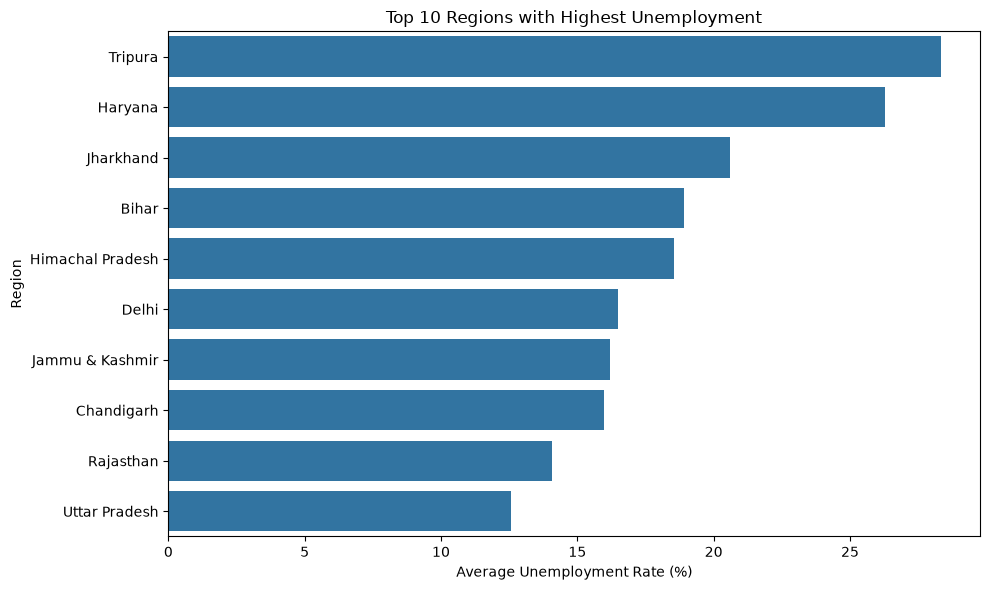

In [27]:
top_10 = region_unemployment.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10.values,
    y=top_10.index
)

plt.title("Top 10 Regions with Highest Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.savefig("../outputs/figures/top_10_regions.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [28]:
import os

print("Saved Graphs:")
print(os.listdir("../outputs/figures"))

Saved Graphs:
['monthly_trend.png', 'rural_vs_urban.png', 'top_10_regions.png', 'unemployment_by_region.png', 'unemployment_distribution.png']


In [29]:
import os

os.makedirs("../outputs/tables", exist_ok=True)

# Regional unemployment summary
region_summary = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

region_summary.to_csv(
    "../outputs/tables/regional_unemployment.csv"
)

# Rural and Urban summary
area_summary = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

area_summary.to_csv(
    "../outputs/tables/area_unemployment.csv"
)

print("Summary tables saved successfully!")

Summary tables saved successfully!


In [30]:
df.to_csv(
    "../data/processed/cleaned_unemployment_data.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [31]:
print("========== PROJECT FINDINGS ==========")

print("Total Records:", len(df))

print("Average Unemployment Rate:",
      round(df['Estimated Unemployment Rate (%)'].mean(), 2), "%")

print("Highest Unemployment Region:",
      region_unemployment.idxmax())

print("Lowest Unemployment Region:",
      region_unemployment.idxmin())

print("\nArea-wise Unemployment:")
print(area_unemployment)

print("\n======================================")

========== PROJECT FINDINGS ==========
Total Records: 740
Average Unemployment Rate: 11.79 %
Highest Unemployment Region: Tripura
Lowest Unemployment Region: Meghalaya

Area-wise Unemployment:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64



# Conclusion

The Unemployment Analysis project helped us understand
the unemployment situation in India using Python.

Through data analysis and visualization, we observed
differences in unemployment rates across various regions
and between rural and urban areas.

The analysis showed that the average unemployment rate
in urban areas was higher than in rural areas in this
historical dataset.

Python libraries such as Pandas, NumPy, Matplotlib,
and Seaborn helped us clean, analyze, and visualize
the data effectively.

This project improved our understanding of data
analysis and visualization techniques.

## Future Scope

- Analyze more recent unemployment data.
- Compare unemployment across different years.
- Study factors affecting unemployment.
- Build a machine learning model to predict trends.

In [2]:
import os
print(os.getcwd())

C:\Users\dell\Unemployment_Analysis\notebooks
